# 🎯 Logistic Regression: from Zero to Confident
### Project: Customer Churn Predictor

**Churn** means a customer leaves (cancels their subscription). Our job: look at a customer and estimate **how likely they are to leave**, so a company can try to keep them.

**How to use this notebook**
- Run cells top to bottom. Every code cell is short and commented.
- Before each code cell: *what we're about to do and why*. After: *what we just saw*.
- Every concept follows the same 7 steps: **idea → analogy → tiny example → math in words → code line by line → common mistake → check yourself**.
- Stuck? Tell your mentor: **"explain simpler"** and the last idea gets a new analogy and a smaller example.
- Unknown word? Look at the **Glossary** right below. It grows as we learn.

**Map of the journey**
1. Theory in plain English
2. Data exploration and preprocessing
3. Logistic regression from scratch (NumPy only)
4. scikit-learn: binary and multi-class (Iris)
5. Metrics: how do we know it's good?
6. Threshold selection as a business decision (₹ costs)
7. Failure modes: class imbalance and calibration
8. Practice: 8 "prove it" questions, 3 coding exercises, 1 extension


## ðŸ“š Glossary (grows as we learn - every new term is added here)

| Term | Plain-English meaning |
|---|---|
| **Classification** | Predicting a category (like 'stays' or 'leaves') instead of a number. |
| **Binary classification** | Classification with exactly two categories, usually called 0 and 1. |
| **Churn** | A customer leaving / cancelling. We label leaving = 1, staying = 0. |
| **Probability** | A number from 0 to 1 saying how likely something is. 0 = impossible, 1 = certain. |
| **Feature** | One input column we use to predict (e.g. months as a customer). |
| **Label / target** | The answer we want to predict (churned or not). |
| **NumPy** | A Python library for fast maths on lists of numbers (arrays). |
| **Odds** | Chance it happens divided by chance it doesn't. p=0.8 gives odds of 4 ('4 to 1'). |
| **Logarithm (ln)** | Answers 'e to what power gives this number?'. ln(1)=0, ln(4)≈1.386. |
| **Log-odds (logit)** | ln(odds). Ranges over all real numbers; 0 means 50/50. |
| **Weight** | A number saying how much a feature pushes the score up or down. The model learns these. |
| **Bias (intercept)** | The starting score when every feature is zero. |
| **Score (z)** | The raw straight-line answer b + w·x before squashing into a probability. |
| **Sigmoid** | The squasher 1/(1+e^-z). Turns any number into a value between 0 and 1. |
| **e (Euler's number)** | A constant ≈ 2.718 used in growth and probability maths. |
| **Linear regression** | Fits a straight line to predict a number. Great for prices, bad for yes/no. |
| **Log-loss (cross-entropy)** | A score that punishes confident wrong predictions heavily. Lower is better. |
| **Likelihood** | The probability, under the model, of seeing exactly the real outcomes. |
| **Maximum likelihood** | Choosing weights that make the real data as likely as possible. |
| **Decision boundary** | The line/surface where the model's probability equals the threshold (usually 0.5). |
| **Threshold** | How sure the model must be before we say 'yes' (act). Often 0.5, but a business choice. |
| **Linear classifier** | A model whose decision boundary is a straight line or flat plane. |
| **EDA** | Exploratory Data Analysis: looking at and plotting the data before modelling. |
| **Preprocessing** | Cleaning and converting raw data into the numeric form a model needs. |
| **DataFrame** | A table in Python (pandas): rows are customers, columns are features. |
| **pandas** | A Python library for working with tables of data. |
| **Class imbalance** | When one answer (e.g. 'stay') is far more common than the other. |
| **NaN** | 'Not a number': Python's marker for a missing value. |
| **One-hot encoding** | Turning a category into separate 0/1 columns, one per category. |
| **Dummy variable trap** | If you keep every one-hot column, they add up to a constant and confuse the model. Drop one. |
| **Train/test split** | Training data teaches the model; test data (hidden) checks it on new customers. |
| **Stratified split** | A split that keeps the same class percentages in train and test. |
| **Mean** | The average. |
| **Standard deviation (std)** | A typical distance of values from the mean (the spread). |
| **Scaling (standardisation)** | Converting values to (x - mean)/std so features share a scale. |
| **Data leakage** | When information from the test set sneaks into training, making results look unfairly good. |
| **Gradient** | The slope of the loss: it points to where the loss grows fastest. We walk the opposite way. |
| **Gradient descent** | Repeatedly nudging the weights downhill on the loss until it stops improving. |
| **Learning rate** | How big each nudge is. Too big = overshoot; too small = painfully slow. |
| **Iteration / epoch** | One full round of computing predictions and updating the weights. |
| **Derivative** | How fast a value changes when you nudge its input (the slope). |
| **Matrix multiplication** | A fast way to compute many weighted sums at once. |
| **scikit-learn (sklearn)** | A Python library with ready-made machine-learning tools. |
| **Regularisation** | A penalty on large weights that discourages the model from over-fitting. |
| **C (in sklearn)** | Inverse penalty strength: big C = weak penalty, small C = strong penalty. |
| **Over-fitting** | Memorising the training data's quirks, so new data does worse. |

# Step 1 - Theory in plain English

We will learn six ideas, in this order: **odds → log-odds → sigmoid → why not linear regression → log-loss → decision boundary**.
First, a setup cell so our code can draw plots and do maths.

### What we're about to do and why
Import the tools once. `numpy` = maths, `matplotlib` = drawing plots. We fix a random seed so you get the same numbers I do.

In [1]:
import numpy as np                    # NumPy: fast maths on arrays of numbers
import matplotlib.pyplot as plt      # matplotlib: draws plots
import warnings; warnings.filterwarnings("ignore")   # hide noisy, harmless warnings
np.random.seed(42)                   # fix randomness so results repeat every run
plt.rcParams["figure.figsize"] = (6, 4)   # default plot size (width, height) in inches
plt.rcParams["axes.grid"] = True          # light grid makes plots easier to read

### What we just saw
Nothing visible, and that's fine: the tools are loaded. (`np` is our shortcut name for NumPy, `plt` for matplotlib.)

---
## 1.0 The problem: a yes/no question
**Idea:** Logistic regression answers a yes/no question by giving a *probability* of "yes".

**Analogy:** Think of a **probability dial** from 0 to 100%. For each customer the model turns the dial to say "I'm 80% sure this person will leave". *Then* a human picks how sure is sure enough to act.

**Name check:** despite the word "regression" in its name, logistic regression is used for **classification**. It's a historical naming accident.

**Common beginner mistake:** thinking the model outputs "yes" or "no". It outputs a **probability**. The yes/no comes later, from a threshold (Step 6).

---
## 1.1 Odds
**Idea (one sentence):** Odds compare how likely something is to happen versus how likely it is *not* to happen.

**Analogy:** Betting odds. "4 to 1" means for every 1 time it fails, it happens 4 times.

**Tiny example by hand:**
- A customer has a probability of leaving of **p = 0.8** (80%).
- Chance of *not* leaving = 1 − 0.8 = **0.2**.
- Odds = 0.8 ÷ 0.2 = **4**. ("4 to 1 they leave")
- If p = 0.5 → odds = 0.5 ÷ 0.5 = **1** ("even odds", a coin flip).
- If p = 0.2 → odds = 0.2 ÷ 0.8 = **0.25** (unlikely).

**The math, every symbol in words:**

`odds = p / (1 − p)`
- `p` = the probability the event happens (a number between 0 and 1).
- `1 − p` = the probability it does not happen.
- `/` = divide.

Odds range from 0 up to infinity (∞). They never go negative.

**Common beginner mistake:** mixing up *odds* and *probability*. Odds of 4 does **not** mean 4% or 40%. It means 80%.

In [2]:
def odds(p):                  # turn a probability p into odds
    return p / (1 - p)       # chance it happens divided by chance it doesn't

for p in [0.2, 0.5, 0.8, 0.99]:        # try four probabilities
    print(f"p = {p:<4}  ->  odds = {odds(p):.2f}")   # print p and its odds (2 decimals)

p = 0.2   ->  odds = 0.25
p = 0.5   ->  odds = 1.00
p = 0.8   ->  odds = 4.00
p = 0.99  ->  odds = 99.00


### What we just saw (code line by line)
- `def odds(p):` defines a reusable recipe named `odds` that takes one input `p`.
- `return p / (1 - p)` hands back the answer of the formula.
- `for p in [...]:` repeats the next line once for each probability in the list.
- `print(f"...{...}")` prints text; the `{}` parts get replaced by real numbers.

Notice p = 0.99 gives odds = 99. Odds explode as p nears 1. That's awkward, so we take one more step.

### ðŸ§  Check yourself

If p = 0.75, what are the odds?

<details><summary>ðŸ‘‰ Click for the answer</summary>

Odds = 0.75 ÷ 0.25 = **3** (3 to 1).

</details>

---
## 1.2 Log-odds (the "logit")
**Refresher: what is a logarithm (log)?** `ln(x)` answers: *"e raised to what power gives x?"* (`e` ≈ 2.718, a special constant.)
- `ln(1) = 0` because e⁰ = 1.
- `ln(e) = 1` because e¹ = e.
- `ln(4) ≈ 1.386`.
- `ln` of a number **below 1 is negative**: `ln(0.25) ≈ −1.386`.
- Logs turn *multiplying* into *adding*: `ln(a×b) = ln(a) + ln(b)`. Keep that, we'll use it later.

**Idea (one sentence):** Log-odds are just the natural log of the odds, which stretches the 0-to-∞ odds onto the whole number line, −∞ to +∞.

**Analogy:** A thermometer that goes below zero. Odds only have "above 0"; log-odds give us a fair scale with a neutral middle (0 = 50/50), positive = "likely yes", negative = "likely no".

**Tiny example by hand:**
- p = 0.8 → odds = 4 → log-odds = ln(4) = **1.386**
- p = 0.5 → odds = 1 → log-odds = ln(1) = **0**
- p = 0.2 → odds = 0.25 → log-odds = ln(0.25) = **−1.386** (mirror image!)

**The math in words:** `log-odds = ln( p / (1 − p) )`, "take the probability, convert to odds, then take the log".

**Why we care:** logistic regression says *the log-odds are a straight-line combination of the features*:
`z = b + w₁·x₁ + w₂·x₂ + …`
- `z` = the log-odds (also called the **score**).
- `b` = the **bias/intercept**, the starting score when all features are 0.
- `w₁, w₂…` = **weights**, how much each feature pushes the score up or down.
- `x₁, x₂…` = the feature values of a customer.

A straight line can freely produce any number from −∞ to +∞, exactly the range log-odds have. That's a perfect match.

In [3]:
def log_odds(p):                 # probability -> log-odds
    return np.log(p / (1 - p))   # np.log is the natural log (ln)

for p in [0.2, 0.5, 0.8]:        # a low, middle and high probability
    print(f"p = {p}  ->  log-odds = {log_odds(p):+.3f}")   # + sign shows positive/negative

p = 0.2  ->  log-odds = -1.386
p = 0.5  ->  log-odds = +0.000
p = 0.8  ->  log-odds = +1.386


### What we just saw
p = 0.2 and p = 0.8 give log-odds of the *same size but opposite sign* (−1.386 and +1.386), and 0.5 gives exactly 0. `np.log` is NumPy's ln. The `:+.3f` inside the print means "3 decimals, always show the sign".

**Common beginner mistake:** calling `log10` or thinking "log" always means base 10. In machine learning, "log" almost always means the **natural log** `ln` (base e).

### ðŸ§  Check yourself

What probability has log-odds of exactly 0?

<details><summary>ðŸ‘‰ Click for the answer</summary>

**0.5.** Odds = 1 and ln(1) = 0.

</details>

---
## 1.3 The sigmoid function (and where it comes from)
**Idea (one sentence):** The sigmoid takes any number and squashes it into a probability between 0 and 1.

**Analogy:** A squasher / dimmer switch. Push in a huge number or a hugely negative number; out comes something between 0 and 1. The middle (0) comes out as exactly 0.5.

**Derivation: one small step per line.** We *start* from "log-odds = z" and solve for p:

| Step | Line | Plain-English note |
|---|---|---|
| 1 | `ln( p / (1−p) ) = z` | Our assumption: the log-odds equal the score z |
| 2 | `p / (1−p) = eᶻ` | Undo the ln by raising e to both sides |
| 3 | `p = eᶻ · (1−p)` | Multiply both sides by (1−p) |
| 4 | `p = eᶻ − eᶻ·p` | Open the bracket |
| 5 | `p + eᶻ·p = eᶻ` | Move the p-term to the left side |
| 6 | `p · (1 + eᶻ) = eᶻ` | Pull p out as a common factor |
| 7 | `p = eᶻ / (1 + eᶻ)` | Divide both sides by (1 + eᶻ) |
| 8 | `p = 1 / (1 + e⁻ᶻ)` | Divide top and bottom by eᶻ (since eᶻ/eᶻ = 1 and 1/eᶻ = e⁻ᶻ) |

**Result:** `σ(z) = 1 / (1 + e⁻ᶻ)`, where `σ` (the Greek letter sigma) is the name of the function, and `e⁻ᶻ` means "e to the power of minus z".

**Tiny example by hand:**
- z = 0 → e⁰ = 1 → σ = 1 / (1+1) = **0.5**
- z = 2 → e⁻² ≈ 0.1353 → σ = 1 / 1.1353 ≈ **0.881**
- z = −2 → e² ≈ 7.389 → σ = 1 / 8.389 ≈ **0.119**
- z = 10 → e⁻¹⁰ ≈ 0.00005 → σ ≈ **0.99995** (almost 1, never exactly 1)

### What we're about to do
Write the sigmoid in code, test it on the numbers we did by hand, then draw it.

In [4]:
def sigmoid(z):                      # squash any number z into (0, 1)
    return 1 / (1 + np.exp(-z))      # np.exp(-z) is e to the power of minus z

for z in [0, 2, -2, 10]:             # the same numbers as our hand example
    print(f"z = {z:>3}  ->  sigmoid = {sigmoid(z):.5f}")

z =   0  ->  sigmoid = 0.50000
z =   2  ->  sigmoid = 0.88080
z =  -2  ->  sigmoid = 0.11920
z =  10  ->  sigmoid = 0.99995


### What we just saw (code line by line)
- `np.exp(-z)` = e⁻ᶻ. NumPy's `exp` computes "e to the power of".
- `1 / (1 + ...)` is the formula exactly as derived.
The printed numbers match our hand work (0.5, 0.881, 0.119, 0.99995). If your hand maths matches the code, you understand it.

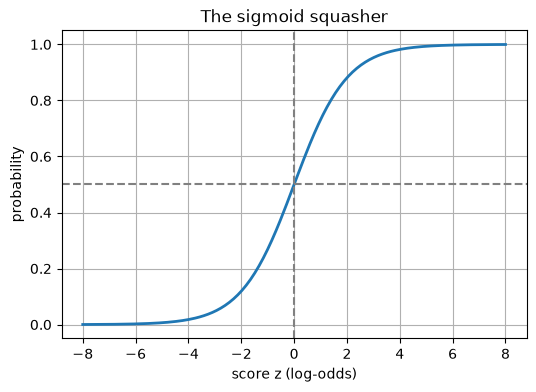

In [5]:
z = np.linspace(-8, 8, 200)         # 200 evenly spaced numbers from -8 to 8
plt.plot(z, sigmoid(z), lw=2)       # draw z on the x-axis, sigmoid(z) on the y-axis
plt.axhline(0.5, color="gray", ls="--")   # dashed line at probability 0.5
plt.axvline(0, color="gray", ls="--")     # dashed line at score 0
plt.xlabel("score z (log-odds)"); plt.ylabel("probability")   # label axes
plt.title("The sigmoid squasher"); plt.show()   # title and display

#### ðŸ“– How to read this plot

- **Axes:** x = the raw score z (can be any number); y = the probability that comes out (0 to 1).
- **A good result looks like:** A smooth 'S'. Big negative scores give probabilities near 0, big positive near 1, and z=0 gives 0.5.
- **A bad result looks like:** A flat line, or a curve that goes below 0 or above 1 (that would not be a probability).
- **What this plot tells us:** No matter how extreme the score, the sigmoid always returns a valid probability. It is steepest around 0, so the model is most 'changeable' near 50/50 and gets more confident slowly at the ends.

**Common beginner mistake:** thinking the sigmoid output is a *guarantee*. σ(z)=0.9 means "the model believes 90%". That is only true if the model is **calibrated** (Step 7b).

### ðŸ§  Check yourself

What is sigmoid(0), and why?

<details><summary>ðŸ‘‰ Click for the answer</summary>

**0.5.** e⁰ = 1, so 1/(1+1) = 0.5. A score of zero means odds of 1, a coin flip.

</details>

### Recap in 3 bullets

- Odds = p/(1−p); log-odds = ln(odds) stretches probabilities to any real number.
- Logistic regression models the log-odds as a straight line: z = b + w·x.
- The sigmoid is the inverse of log-odds: it turns the score z back into a probability.

**If you remember only one thing:** the sigmoid turns any score into a probability between 0 and 1.

---
## 1.4 Why not just use linear regression for yes/no?
**Idea (one sentence):** A straight line can output −5 or 12, which are not probabilities, and it is thrown off by extreme points.

**Analogy:** Using a ruler to predict a light switch. A switch is only ON or OFF, but a ruler happily reads "−3 centimeters" or "17 centimeters" of on-ness.

**Tiny example by hand:** Suppose a line predicts `y = 0.1·tenure − 0.2`. A customer with tenure 0 gets **−0.2** (a "negative 20% chance"), and one with tenure 12 gets **1.0**; tenure 20 gets **1.8** ("180%"). Impossible.

**Two failures:**
1. **Impossible outputs**, below 0 or above 1.
2. **Sensitive to far-away points.** One super-loyal customer drags the line and shifts predictions for everyone else.
We'll *see* this below.

### What we're about to do
Make 40 toy customers (x = months with company; y = 1 if churned). Fit a straight line (linear regression) and a sigmoid curve (we'll hand-pick its shape for now) and compare.

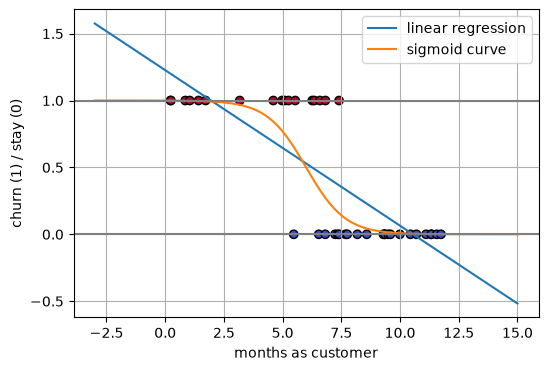

In [6]:
rng = np.random.RandomState(0)                       # a reproducible random generator
x = np.sort(rng.uniform(0, 12, 40))                  # 40 tenures between 0 and 12 months
y = (x + rng.normal(0, 2, 40) < 6).astype(int)       # short tenure -> likely churn (1), with noise
slope, icpt = np.polyfit(x, y, 1)                    # fit the best straight line to y
xs = np.linspace(-3, 15, 100)                        # x range to draw lines over (beyond data)
plt.scatter(x, y, c=y, cmap="coolwarm", edgecolor="k")   # draw the customers
plt.plot(xs, slope*xs + icpt, label="linear regression")  # the straight line
plt.plot(xs, sigmoid(-1.2*(xs-6)), label="sigmoid curve")  # a hand-picked sigmoid
plt.axhline(0, c="gray"); plt.axhline(1, c="gray")   # the legal range 0..1
plt.xlabel("months as customer"); plt.ylabel("churn (1) / stay (0)"); plt.legend(); plt.show()

#### ðŸ“– How to read this plot

- **Axes:** x = months as customer; y = churned (1) or stayed (0). Dots are customers (red = churned), the lines are predictions.
- **A good result looks like:** A prediction line that stays between 0 and 1 and bends toward the dots at each end, like the sigmoid.
- **A bad result looks like:** A line that crosses below 0 or above 1 (impossible probabilities), like the straight line at the far left/right.
- **What this plot tells us:** The straight line leaves the 0-to-1 box, so it can't be read as a probability. The sigmoid hugs 0 and 1 and respects the rules.

### What we just saw (code line by line)
- `rng.uniform(0, 12, 40)` draws 40 random tenures; `np.sort` orders them.
- `(x + noise < 6).astype(int)` makes churn = 1 when (tenure + a bit of noise) is under 6, turning True/False into 1/0.
- `np.polyfit(x, y, 1)` finds the best straight line; it returns its slope and intercept.
- `plt.scatter` draws dots coloured by `y`; `plt.plot` draws the two prediction curves.

**Common beginner mistake:** "clipping" a linear model's output to 0–1 and calling it logistic regression. Clipping fixes the range but not the bad shape or the training problems.

### ðŸ§  Check yourself

Name one reason linear regression is a poor choice for yes/no.

<details><summary>ðŸ‘‰ Click for the answer</summary>

Its predictions can be below 0 or above 1, so they aren't probabilities. (Also: extreme points pull the line.)

</details>

### Recap in 3 bullets

- Linear regression can output impossible values (−0.2, 1.8) as 'probabilities'.
- The sigmoid fixes the range: the output is always between 0 and 1.
- Logistic regression = straight line for the score, then a sigmoid to get a probability.

**If you remember only one thing:** use the sigmoid on top of the straight line so predictions are real probabilities.

---
## 1.5 Log-loss (cross-entropy): how wrong is the model?
**Idea (one sentence):** Log-loss is a score that punishes the model more, the more confident it was in the wrong answer.

**Analogy:** A quiz show where you bet points. Being right with high confidence earns almost no penalty; being *confidently wrong* costs a fortune; being unsure costs a medium amount.

**Tiny example by hand:** The customer **really did churn (y = 1)**. Loss for one customer = `−ln(p)` where p = probability we gave to the truth.
- Model said p = 0.9 → loss = −ln(0.9) = **0.105** (small, good!)
- Model said p = 0.5 → loss = −ln(0.5) = **0.693**
- Model said p = 0.1 → loss = −ln(0.1) = **2.303** (confidently wrong, big!)
- Model said p = 0.01 → loss = **4.605** (huge!)
If the customer **stayed (y = 0)**, we use `−ln(1−p)` instead: the probability we gave to "stays".

**Derivation: one small step per line.**
Let `p` = model's probability of churn, `y` = truth (1 or 0).

| Step | Line | Plain-English note |
|---|---|---|
| 1 | `P(one customer) = p^y · (1−p)^(1−y)` | If y=1 this is p; if y=0 it is (1−p). It's "the probability the model gave the truth" |
| 2 | `L = P₁ · P₂ · … · Pₙ` | **Likelihood:** probability of all n customers' truths together (multiply them) |
| 3 | `ln L = ln P₁ + ln P₂ + … + ln Pₙ` | Take ln: multiplying becomes adding (log rule from our refresher). Sums are stable and easy |
| 4 | `ln P = y·ln(p) + (1−y)·ln(1−p)` | ln turns the powers into multipliers |
| 5 | `Loss = −(1/n) · Σ [ y·ln(p) + (1−y)·ln(1−p) ]` | Flip the sign (we want to *minimize* a loss, not maximize) and average over n |

`Σ` (capital sigma) just means "add up over all customers", and `1/n` turns the total into an average.
So **minimizing log-loss = finding the weights that make the real outcomes as likely as possible** (this is called *maximum likelihood*).

**Why not just count mistakes?** Counting mistakes jumps in steps, so we can't tell which direction to nudge the weights. Log-loss is smooth, so gradient descent (Step 3) can follow it downhill.

In [7]:
def log_loss(y, p, eps=1e-12):                 # average log-loss over all customers
    p = np.clip(p, eps, 1 - eps)               # keep p away from exactly 0 or 1 (ln(0) breaks)
    return -np.mean(y*np.log(p) + (1-y)*np.log(1-p))   # the formula from step 5

y_true = np.array([1, 1, 0, 0])                # real outcomes
print("good model :", log_loss(y_true, np.array([.9, .8, .1, .2])))   # right and confident
print("unsure     :", log_loss(y_true, np.array([.5, .5, .5, .5])))   # coin flips
print("wrong+sure :", log_loss(y_true, np.array([.1, .2, .9, .8])))   # confidently wrong

good model : 0.164252033486018
unsure     : 0.6931471805599453
wrong+sure : 1.956011502714073


### What we just saw (code line by line)
- `np.clip(p, eps, 1-eps)` forces p into a safe range. Without it, p = 0 would give ln(0) = −∞, a crash.
- `np.mean(...)` is the `(1/n) Σ` part: add up and divide by count.
- `y*np.log(p)` only counts when y=1; `(1-y)*np.log(1-p)` only counts when y=0.
Good model ≈ 0.16, coin flips ≈ 0.693, confidently wrong ≈ 1.96. Lower is better.

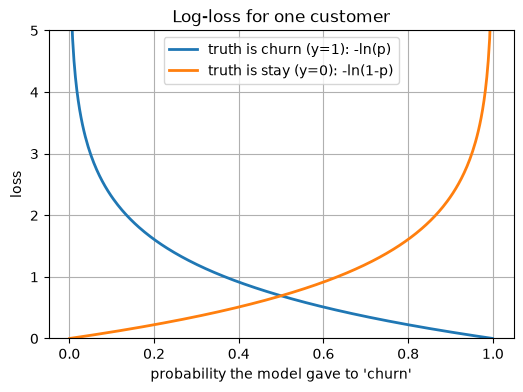

In [8]:
p = np.linspace(0.001, 0.999, 300)           # possible probabilities for a true-churner
plt.plot(p, -np.log(p), lw=2, label="truth is churn (y=1): -ln(p)")      # loss when y=1
plt.plot(p, -np.log(1-p), lw=2, label="truth is stay (y=0): -ln(1-p)")   # loss when y=0
plt.ylim(0, 5); plt.xlabel("probability the model gave to 'churn'"); plt.ylabel("loss")
plt.legend(); plt.title("Log-loss for one customer"); plt.show()

#### ðŸ“– How to read this plot

- **Axes:** x = the probability the model gave to 'churn'; y = the penalty (loss) for one customer.
- **A good result looks like:** Loss near 0: the model put p close to 1 for a real churner (blue curve, right side) or close to 0 for a stayer (orange curve, left side).
- **A bad result looks like:** Loss shooting up: p near 0 for a real churner, or near 1 for a stayer (confident and wrong).
- **What this plot tells us:** The penalty grows sharply, not gently, as the model becomes confidently wrong. That pushes the model to be honest about its uncertainty.

**Common beginner mistake:** forgetting to clip probabilities, and then a single p of exactly 0 or 1 makes the loss `inf` or `nan`.

### ðŸ§  Check yourself

The customer churned (y=1). Model gave p=0.25. What is the loss for this customer?

<details><summary>ðŸ‘‰ Click for the answer</summary>

−ln(0.25) = **1.386**.

</details>

### Recap in 3 bullets

- Log-loss = average of −ln(probability given to the truth).
- It comes from maximum likelihood: multiply probabilities, take logs, flip the sign.
- It punishes confident wrong answers very hard and is smooth, so we can minimize it.

**If you remember only one thing:** log-loss rewards honest, correct probabilities and brutally punishes confident mistakes.

---
## 1.6 Decision boundaries
**Idea (one sentence):** The decision boundary is the line where the model switches from saying "stay" to "leave".

**Analogy:** A fence in a field. Customers on one side are predicted to leave, on the other side to stay. The fence stands where the probability is exactly 50% (or whatever threshold we pick).

**Tiny example by hand:** with two features, `z = −3 + 1·x₁ + 1·x₂`.
- Probability = 0.5 exactly when z = 0 (we showed sigmoid(0)=0.5).
- So the boundary is `x₁ + x₂ = 3`, a straight line.
- Point (1, 1): z = −1 → p ≈ 0.27 → "stay". Point (3, 2): z = +2 → p ≈ 0.88 → "leave".

**The math in words:** boundary is where `b + w₁x₁ + w₂x₂ = 0`. Since the score is a straight line in the features, the boundary is a straight line (a flat plane with more features). That is why logistic regression is called a **linear classifier**.
We draw the real one in Step 3.

In [9]:
def score(x1, x2):                  # the hand example: z = -3 + x1 + x2
    return -3 + x1 + x2

for pt in [(1, 1), (3, 2), (1.5, 1.5)]:           # three customers (x1, x2)
    z = score(*pt)                                # their score
    print(pt, f"z={z:+.1f}  p={sigmoid(z):.2f}")  # score and probability

(1, 1) z=-1.0  p=0.27
(3, 2) z=+2.0  p=0.88
(1.5, 1.5) z=+0.0  p=0.50


### What we just saw
(1,1) gives p=0.27 (stay), (3,2) gives p=0.88 (leave), and (1.5,1.5) sits exactly on the fence (z=0, p=0.50). `*pt` unpacks the pair (1,1) into the two inputs x1 and x2.

**Common beginner mistake:** assuming the boundary is always at probability 0.5. 0.5 is just a default. In Step 6 we'll move it to save money.

### ðŸ§  Check yourself

A model has z = 2 − x₁ (one feature). At what x₁ is the boundary?

<details><summary>ðŸ‘‰ Click for the answer</summary>

Set z = 0: 2 − x₁ = 0 → **x₁ = 2**.

</details>

### Recap in 3 bullets

- The boundary is where the score z is 0 (probability = threshold).
- Because z is a straight line in the features, the boundary is a straight line/plane.
- Moving the threshold moves the fence, a choice we'll make by money (Step 6).

**If you remember only one thing:** the decision boundary is simply where the model's probability crosses your chosen threshold.

---
# ✅ Step 1 summary
**Recap in 3 bullets**
- Probability → odds → log-odds; logistic regression makes log-odds a straight line.
- Sigmoid converts the score back into a 0-to-1 probability; log-loss trains it.
- The decision boundary is where probability hits the threshold.

**If you remember only one thing:** logistic regression = *straight-line score → sigmoid → probability → threshold → decision*.

# Step 2 - EDA and preprocessing

**EDA** (Exploratory Data Analysis) means *looking at the data before modelling*, like reading a recipe and checking ingredients before cooking. Then we **preprocess**: turn the raw table into numbers a model can digest.

### What we're about to do and why
Load the **Telco Customer Churn** dataset (7,043 customers of a phone/internet company). We try the internet first, and cache a copy in a `data/` folder (git-ignored: we never commit datasets). If the download fails, we generate a realistic imbalanced fake dataset with `make_classification` (90% / 10%) so the notebook still runs.

In [10]:
import os, pandas as pd
from sklearn.datasets import make_classification
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
os.makedirs("data", exist_ok=True)                     # folder for the cached copy
try:
    df = pd.read_csv("data/telco.csv") if os.path.exists("data/telco.csv") else pd.read_csv(URL)
    df.to_csv("data/telco.csv", index=False)           # cache it for next time
    SYNTHETIC = False
except Exception as e:                                 # no internet -> synthetic fallback
    Xs, ys = make_classification(n_samples=7000, n_features=8, weights=[0.9, 0.1], random_state=42)
    df = pd.DataFrame(Xs, columns=[f"f{i}" for i in range(8)]); df["Churn"] = np.where(ys == 1, "Yes", "No")
    SYNTHETIC = True
print("synthetic fallback used:", SYNTHETIC, "| shape:", df.shape)
df.head(3)

synthetic fallback used: False | shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


### What we just saw (code line by line)
- `try: ... except:` means "attempt this; if it fails, do the backup plan".
- `pd.read_csv(URL)` downloads a CSV file into a DataFrame (a table).
- `make_classification(..., weights=[0.9, 0.1])` makes fake data where 90% are class 0 and 10% class 1.
- `df.head(3)` shows the first 3 rows. Each row = one customer.

### Look at the columns and spot problems

In [11]:
print(df.dtypes.value_counts())               # how many text (object) vs number columns
print("missing values:", df.isna().sum().sum())   # count of truly empty cells
if not SYNTHETIC:
    # TotalCharges is text because some cells are a blank space ' '
    print("blank TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())

object     18
int64       2
float64     1
Name: count, dtype: int64
missing values: 0
blank TotalCharges: 11


### What we just saw
`TotalCharges` should be a number but is *text*, because 11 customers have a blank (they're brand-new, tenure = 0, so they've paid nothing yet). Real data is messy; always check types.

### Clean the data
**Why:** a model can't do maths on a blank string. We convert to numbers; blanks become `NaN` ("not a number"), then fill them with **0** because these customers genuinely haven't been charged yet. (Filling with the average would be wrong here: we *know* the true value is 0.)
We also drop `customerID`: it's a unique label with no predictive meaning (keeping it would let a model memorize people).

In [12]:
if not SYNTHETIC:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")  # text -> number; blanks -> NaN
    df["TotalCharges"] = df["TotalCharges"].fillna(0)      # new customers have paid 0
    df = df.drop(columns=["customerID"])                   # an ID is not a real feature
df["Churn"] = (df["Churn"] == "Yes").astype(int)           # target: Yes -> 1, No -> 0
print(df["Churn"].value_counts(normalize=True).round(3))  # share of each class

Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


### What we just saw
About **26.5%** churn. That's **imbalanced** (more stayers than leavers). It matters a lot later (Steps 5-7).
`errors="coerce"` means "if you can't convert it, put NaN instead of crashing". `normalize=True` shows fractions instead of counts.

**Common beginner mistake:** filling missing values with the mean *automatically*. Always ask *why* it's missing first.

### ðŸ§  Check yourself

Why did we drop `customerID`?

<details><summary>ðŸ‘‰ Click for the answer</summary>

It's a unique label, not a real pattern. A model could memorize it and fail on new customers.

</details>

### Plot 1: how imbalanced is it, and who churns?

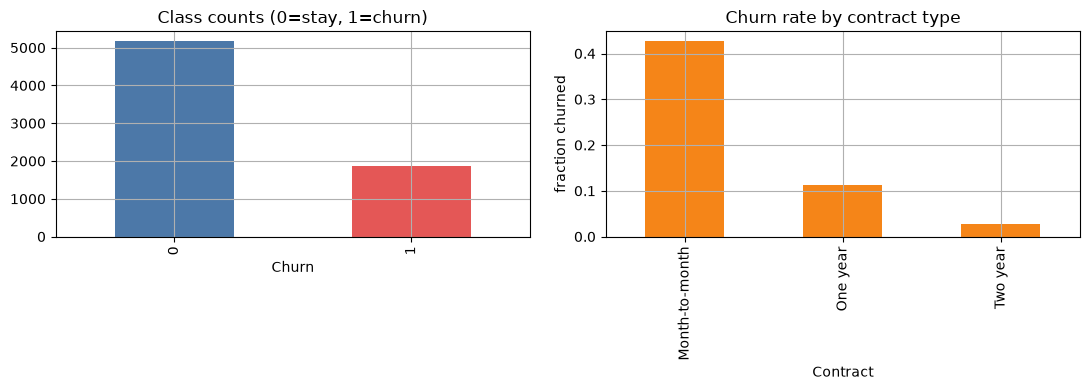

In [13]:
if not SYNTHETIC:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))                    # two plots side by side
    df["Churn"].value_counts().plot.bar(ax=ax[0], color=["#4c78a8", "#e45756"])   # class counts
    ax[0].set_title("Class counts (0=stay, 1=churn)")
    df.groupby("Contract")["Churn"].mean().plot.bar(ax=ax[1], color="#f58518")   # churn rate by contract
    ax[1].set_title("Churn rate by contract type"); ax[1].set_ylabel("fraction churned")
    plt.tight_layout(); plt.show()

#### ðŸ“– How to read this plot

- **Axes:** Left: x = class (0 stay, 1 churn), y = number of customers. Right: x = contract type, y = fraction of those customers who churned.
- **A good result looks like:** Left: balanced bars (not our case). Right: clear differences between groups = a useful feature.
- **A bad result looks like:** Right: all bars the same height would mean the feature tells us nothing.
- **What this plot tells us:** Stayers outnumber churners ~3-to-1, and month-to-month customers churn far more (~43%) than two-year customers (~3%). Contract is a strong signal.

### Plot 2: numeric features
We compare average tenure, monthly and total charges for stayers vs churners.

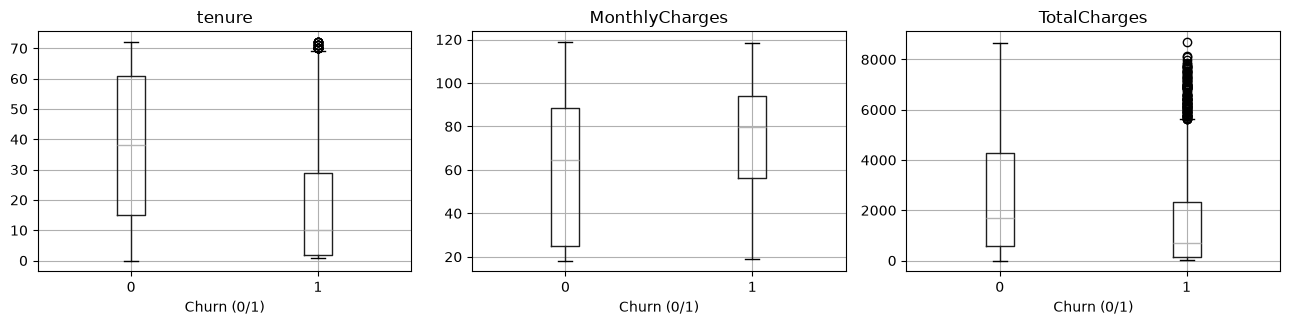

In [14]:
if not SYNTHETIC:
    num = ["tenure", "MonthlyCharges", "TotalCharges"]               # the numeric columns
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
    for a, c in zip(ax, num):                                         # one box plot per column
        df.boxplot(column=c, by="Churn", ax=a)                        # compare churn=0 vs churn=1
        a.set_title(c); a.set_xlabel("Churn (0/1)")
    plt.suptitle(""); plt.tight_layout(); plt.show()

#### ðŸ“– How to read this plot

- **Axes:** x = churn group (0/1); y = the feature value. Each box shows the middle 50% of customers, the line is the median (typical value).
- **A good result looks like:** Boxes for the two groups sit at clearly different heights (the feature separates them).
- **A bad result looks like:** Boxes that overlap almost completely (feature barely helps).
- **What this plot tells us:** Churners have much lower tenure (they leave early) and somewhat higher monthly charges. Tenure is a strong feature.

### ðŸ§  Check yourself

Which plot told us the classes are imbalanced?

<details><summary>ðŸ‘‰ Click for the answer</summary>

The left bar chart: the 'stay' bar is about 3x taller than the 'churn' bar.

</details>

---
## 2.2 Encoding: turning words into numbers
**Idea:** A model can only multiply numbers, so words like "Month-to-month" must become numbers.

**Analogy:** Filling in a form with tick-boxes. "Contract type?" becomes three boxes; tick exactly one.

**Tiny example by hand:** Contract has 3 values. **One-hot encoding** makes one 0/1 column each:
| Contract | is_OneYear | is_TwoYear |
|---|---|---|
| Month-to-month | 0 | 0 |
| One year | 1 | 0 |
| Two year | 0 | 1 |
We drop one column (`drop_first`): "month-to-month" is already shown by both being 0. Keeping all three would let the columns predict each other perfectly (**the dummy variable trap**), which makes weights unstable.

**Why not just 0, 1, 2?** That would claim "Two year" is *twice* "One year" and the model would draw a straight line through meaningless numbers. Categories have no order, so each gets its own column.

**Math in words:** the model computes `z = b + w₁x₁ + …`. Each 0/1 column gets its own weight, so each category gets its own "push" on the score.

**Common beginner mistake:** label-encoding unordered categories as 0,1,2,3.

In [15]:
if not SYNTHETIC:
    y = df["Churn"].values                              # the target as a NumPy array
    X = df.drop(columns="Churn")                        # all other columns are features
    X = pd.get_dummies(X, drop_first=True, dtype=int)   # one-hot encode all text columns
else:
    y = df["Churn"].map({"No": 0, "Yes": 1}).values if df["Churn"].dtype == object else df["Churn"].values
    X = df.drop(columns="Churn")
print("features:", X.shape[1]); X.iloc[:2, :8]

features: 30


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes
0,0,1,29.85,29.85,0,1,0,0
1,0,34,56.95,1889.50,1,0,0,1


### What we just saw
Our 19 original columns became about **30** numeric columns. `pd.get_dummies` finds every text column and does the one-hot encoding for us; `drop_first=True` avoids the dummy variable trap.

### ðŸ§  Check yourself

A column 'City' has 5 cities. How many one-hot columns after `drop_first=True`?

<details><summary>ðŸ‘‰ Click for the answer</summary>

**4.** The 5th city is the case where all four are 0.

</details>

---
## 2.3 Train/test split, then scaling
**Idea (split):** Hide some customers from the model while it learns, then test it on them. Otherwise we can't know if it truly learned or just memorised.

**Analogy:** A student who practises on past papers (train) and is then graded on a brand-new exam (test).

**Stratified:** we keep the same churn percentage (~26.5%) in both groups, like a fair-shuffled deck. We keep **20%** for testing.

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,        # 20% of customers are hidden for testing
    stratify=y,                 # keep the same churn % in both parts
    random_state=42)            # same shuffle every run
print(len(X_train), len(X_test), "| churn rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

5634 1409 | churn rate train/test: 0.265 0.265


### What we just saw
About 5,634 train and 1,409 test rows, with almost identical churn rates (~0.265). That's what `stratify=y` bought us.

---
## Scaling
**Refresher: mean and standard deviation (std).**
- **Mean** = average. Values 2, 4, 6 → mean = (2+4+6)/3 = **4**.
- **Variance** = average squared distance from the mean: ((2−4)²+(4−4)²+(6−4)²)/3 = (4+0+4)/3 = 2.67.
- **Std** = square root of variance = **1.63**. It's a "typical distance from the mean".

**Idea:** Put every feature on the same scale so no feature wins just because its numbers are big.

**Analogy:** Comparing a person's height in metres with their salary in rupees: the salary's huge numbers drown out everything unless you convert both to a "how far from typical" scale.

**Tiny example by hand:** tenure values 2, 4, 6 (mean 4, std 1.63) → z-scores = (value − mean) / std = **−1.22, 0, +1.22**. A z-score says "how many stds above/below average".

**Math in words:** `x_scaled = (x − mean) / std`. Subtract the typical value, then divide by the typical spread.

**Why logistic regression needs it:** (1) gradient descent trains far faster and more smoothly when features share a scale; (2) weights become comparable, so a bigger weight = a stronger feature; (3) regularisation (sklearn's default penalty) punishes big weights unfairly if a feature has huge numbers.

**Common beginner mistake (a serious one, "data leakage"):** computing the mean/std on the *whole* dataset before splitting. The test set's information leaks into training. Always `fit` the scaler on **train only**, then only `transform` the test.

In [17]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()                         # the tool that does (x - mean) / std
Xtr = scaler.fit_transform(X_train)               # learn mean/std from TRAIN only, then apply
Xte = scaler.transform(X_test)                    # apply the same train mean/std to TEST
print("train mean ~", Xtr.mean().round(3), "| train std ~", Xtr.std().round(3))
print("shape:", Xtr.shape, Xte.shape)

train mean ~ -0.0 | train std ~ 1.0
shape: (5634, 30) (1409, 30)


### What we just saw (code line by line)
- `StandardScaler()` creates the scaler.
- `fit_transform(X_train)` = *fit* (measure each column's mean/std) then *transform* (apply the formula).
- `transform(X_test)` re-uses the **train** numbers. That's what prevents leakage.
- After scaling, the train mean is ~0 and std ~1.

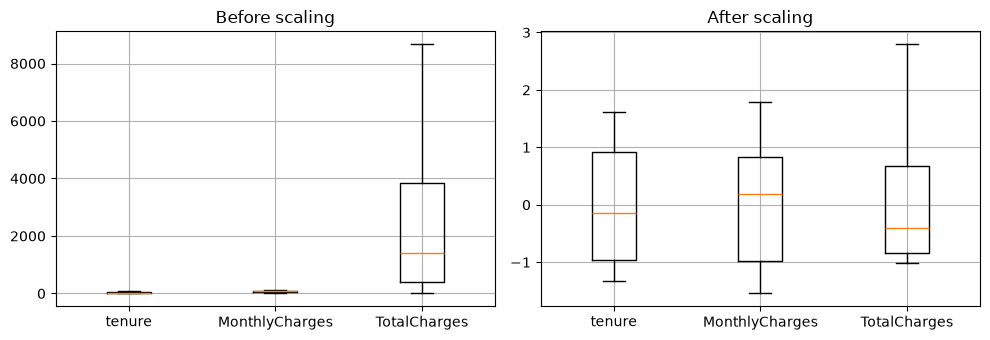

In [18]:
cols = ["tenure", "MonthlyCharges", "TotalCharges"] if not SYNTHETIC else list(X.columns[:3])
idx = [list(X.columns).index(c) for c in cols]     # column positions of these features
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].boxplot(X_train.iloc[:, idx].values, tick_labels=cols); ax[0].set_title("Before scaling")
ax[1].boxplot(Xtr[:, idx], tick_labels=cols); ax[1].set_title("After scaling")
plt.tight_layout(); plt.show()

#### ðŸ“– How to read this plot

- **Axes:** x = the feature; y = its value. Box plots again (box = middle half of customers).
- **A good result looks like:** After scaling, all boxes are centred near 0 and have similar heights.
- **A bad result looks like:** Before scaling, TotalCharges (thousands) dwarfs tenure (tens). That would be a bad starting point for gradient descent.
- **What this plot tells us:** Scaling rescales every feature to a common yardstick without changing the shape of the data.

### ðŸ§  Check yourself

Why do we fit the scaler on train data only?

<details><summary>ðŸ‘‰ Click for the answer</summary>

To avoid data leakage: the test set must stay a true 'unseen exam'.

</details>

### Recap in 3 bullets

- Clean and explore first: wrong types and imbalance show up here.
- One-hot encode categories (drop one column); never use 0,1,2 for unordered groups.
- Split first (stratified), then fit the scaler on train only.

**If you remember only one thing:** the test set must stay untouched until the very end, so any preprocessing is learned from train only.

---
# ✅ Step 2 summary
**Recap in 3 bullets**
- ~26.5% of customers churn, so the data is imbalanced; contract and tenure are strong signals.
- Categories become 0/1 columns; numbers get z-scored.
- We have `Xtr, Xte, y_train, y_test` ready for modelling.

**If you remember only one thing:** split first, then learn all preprocessing from the training data alone.

# Step 3 - Logistic regression from scratch (NumPy only)

Now we build the engine ourselves with only NumPy: **sigmoid → loss → gradient descent → predict**. Then we draw the decision boundary and check that scikit-learn (a ready-made library) gets the same answer.

---
## 3.1 Two refreshers
**Derivative (slope).** A derivative tells you *how fast something changes when you nudge its input.*
- `f(x) = x²`. At x = 3, f = 9. At x = 3.01, f = 9.0601. Change = 0.0601 over a nudge of 0.01 → slope ≈ **6**.
- The derivative of x² is 2x, and at x = 3 that is **6** ✓.
- Slope positive → going right raises f. Slope negative → going right lowers f.
- **Chain rule:** for "a function of a function", multiply the slopes: if `y = f(g(x))` then `dy/dx = f'(g) · g'(x)`.
- Notation: `dL/dw` reads "how much does L change per tiny change in w".

**Matrix multiplication.** For a customer's features `x = [2, 3]` and weights `w = [0.5, −1]`, the score is the **dot product**: `2×0.5 + 3×(−1) = 1 − 3 = −2`. A matrix `X` has one row per customer; `X @ w` gives *every* customer's score at once.
- `Xᵀ` (X transposed) flips rows and columns.
- Rule: `(rows × cols) @ (cols × 1)` gives `(rows × 1)`.

In [19]:
X_demo = np.array([[2, 3], [1, 0], [0, 4]])      # 3 customers, 2 features each
w_demo = np.array([0.5, -1])                      # 2 weights
print("scores:", X_demo @ w_demo)                 # row1: 2*.5+3*-1 = -2 ; row2: .5 ; row3: -4

scores: [-2.   0.5 -4. ]


### What we just saw
`@` is NumPy's matrix multiplication. We got three scores in one line: `[-2, 0.5, -4]`: exactly the hand result for row 1.

---
## 3.2 Gradient descent
**Idea (one sentence):** Start with random weights, measure how wrong we are, nudge the weights a little in the direction that reduces the loss, and repeat.

**Analogy:** Walking down a foggy hill. You can't see the valley, but you can feel the slope under your feet. Take a small step downhill, feel again, repeat.

**Tiny example by hand (one weight):** loss `L(w) = (w − 3)²` (minimum at w = 3). Slope = `2(w−3)`.
- Start w = 0, learning rate 0.1. Slope = −6. Update: `w = 0 − 0.1×(−6) = 0.6`.
- Now slope = 2(0.6−3) = −4.8 → `w = 0.6 + 0.48 = 1.08`.
- Next → 1.464 → … → creeps to 3.
The minus sign in the update is "go *against* the slope = downhill".

**The gradient for logistic regression, derived one step at a time.** For one customer: score `z = w·x + b`, probability `p = σ(z)`, loss `L = −[y ln p + (1−y) ln(1−p)]`.

| Step | Line | Plain-English note |
|---|---|---|
| 1 | `dp/dz = p(1−p)` | The sigmoid's slope (a known result: σ' = σ(1−σ)) |
| 2 | `dL/dp = −y/p + (1−y)/(1−p)` | Slope of the loss w.r.t. p (slope of ln p is 1/p) |
| 3 | `dL/dz = dL/dp · dp/dz` | Chain rule: multiply the two slopes |
| 4 | `= [−y/p + (1−y)/(1−p)] · p(1−p)` | Plug in steps 1 and 2 |
| 5 | `= −y(1−p) + (1−y)p` | The p and (1−p) cancel the fractions |
| 6 | `= −y + yp + p − yp = p − y` | Expand; the yp terms cancel |
| 7 | `dz/dw = x` and `dz/db = 1` | z is a straight line, so its slope is the feature itself |
| 8 | `dL/dw = (p − y)·x`, `dL/db = (p − y)` | Chain rule again |

**Beautiful result:** the slope is simply **(prediction − truth) × feature**. Averaged over n customers, in matrix form:

`gradient_w = (1/n) · Xᵀ (p − y)`  and  `gradient_b = mean(p − y)`

Symbols: `X` = feature table, `p` = vector of predicted probabilities, `y` = vector of truths, `n` = number of customers.

**Update rule:** `w ← w − lr · gradient_w` and `b ← b − lr · gradient_b` (`lr` = learning rate, `←` means "replace with").

**Common beginner mistake:** a learning rate that's too big. The loss goes up or becomes `nan` instead of down, because each step overshoots the valley.

### ðŸ§  Check yourself

If the true y=1 but the model predicts p=0.2, is (p−y) positive or negative, and what does the update do to the score?

<details><summary>ðŸ‘‰ Click for the answer</summary>

(p − y) = −0.8 (negative). The update `w − lr·(negative)·x` *increases* the weights for this x, raising the score toward churn. ✔

</details>

### What we're about to do
Write the five building blocks as small functions. Read each comment: every line is explained.

In [20]:
def sigmoid(z):                                  # squash any score into (0, 1)
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))   # clip stops overflow for huge |z|

def predict_proba(X, w, b):                     # probability of class 1 for every row of X
    return sigmoid(X @ w + b)                   # score = X @ w + b, then squash

def log_loss(y, p, eps=1e-12):                  # average log-loss (Step 1.5)
    p = np.clip(p, eps, 1 - eps)                # avoid ln(0)
    return -np.mean(y*np.log(p) + (1-y)*np.log(1-p))

In [21]:
def fit(X, y, lr=0.1, n_iter=1000):             # gradient descent training loop
    n, d = X.shape                              # n customers, d features
    w, b, history = np.zeros(d), 0.0, []        # start at all-zero weights
    for _ in range(n_iter):                     # repeat n_iter times
        p = predict_proba(X, w, b)              # current predictions
        w -= lr * (X.T @ (p - y)) / n           # nudge weights: lr * (1/n) X^T (p - y)
        b -= lr * np.mean(p - y)                # nudge bias
        history.append(log_loss(y, p))          # remember the loss to plot later
    return w, b, history

def predict(X, w, b, threshold=0.5):            # hard yes/no using the threshold
    return (predict_proba(X, w, b) >= threshold).astype(int)

### What we just saw (code line by line)
- `np.clip(z, -500, 500)` keeps `exp` from overflowing for very large scores.
- `X @ w + b` is the straight-line score for all customers at once.
- `np.zeros(d)` starts all weights at 0 (fine for logistic regression: its loss has a single valley).
- `X.T @ (p - y) / n` is the gradient formula we derived, line for line.
- `w -= lr * ...` means `w = w - lr * ...`, the downhill step.
- `predict` turns probabilities into 0/1 by comparing against the threshold.

**Common beginner mistake:** forgetting the bias `b` (the model can then only draw boundaries through the origin).

### ðŸ§  Check yourself

Why do we start with all-zero weights and still get a good answer?

<details><summary>ðŸ‘‰ Click for the answer</summary>

Logistic regression's loss is bowl-shaped (convex), so gradient descent reaches the single bottom no matter where it starts.

</details>

---
## 3.3 A 2D toy version: see the decision boundary
**Why:** with 30 features we can't draw anything. With **two** features we can draw the actual fence (Step 1.6).
We create 300 fake customers with 2 features, scale them, and train our scratch model.

In [22]:
from sklearn.datasets import make_classification
Xt, yt = make_classification(n_samples=300, n_features=2, n_redundant=0, n_informative=2,
                             n_clusters_per_class=1, class_sep=0.8, flip_y=0.08, random_state=3)   # 2 clusters
Xt = (Xt - Xt.mean(0)) / Xt.std(0)                 # scale: subtract mean, divide by std
w_t, b_t, hist_t = fit(Xt, yt, lr=0.5, n_iter=3000) # train OUR model
print("weights:", w_t.round(3), "bias:", round(b_t, 3), "| final loss:", round(hist_t[-1], 4))

weights: [-5.104 -3.203] bias: -0.067 | final loss: 0.1924


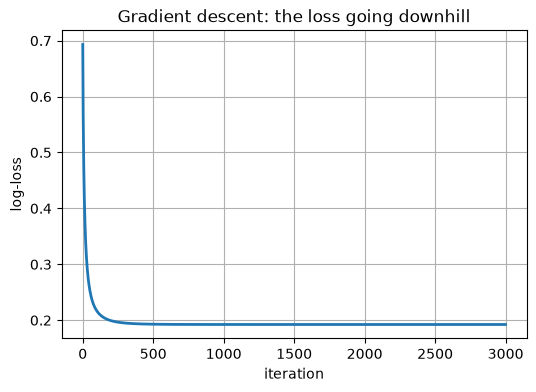

In [23]:
plt.plot(hist_t, lw=2); plt.xlabel("iteration"); plt.ylabel("log-loss")
plt.title("Gradient descent: the loss going downhill"); plt.show()

#### ðŸ“– How to read this plot

- **Axes:** x = iteration number (how many steps we have taken); y = log-loss.
- **A good result looks like:** A curve that drops quickly then flattens (we reached the valley floor).
- **A bad result looks like:** A curve that rises, zig-zags, or stays flat at the start (learning rate wrong or a bug).
- **What this plot tells us:** The loss falls smoothly, so our gradient formula and learning rate work. The flat tail means more iterations would not help.

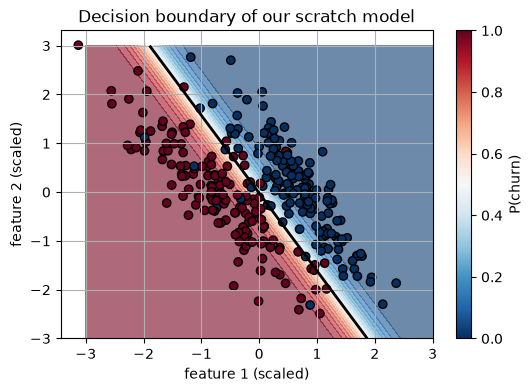

In [24]:
g = np.linspace(-3, 3, 200)                         # grid of x1 and x2 values
xx, yy = np.meshgrid(g, g)                          # every (x1, x2) combination
grid = np.c_[xx.ravel(), yy.ravel()]                # flatten into a list of points
pg = predict_proba(grid, w_t, b_t).reshape(xx.shape)   # probability at every grid point
plt.contourf(xx, yy, pg, levels=20, cmap="RdBu_r", alpha=.6)   # colour = probability
plt.contour(xx, yy, pg, levels=[0.5], colors="k", linewidths=2)  # the p=0.5 fence
plt.scatter(Xt[:,0], Xt[:,1], c=yt, cmap="RdBu_r", edgecolor="k")  # customers
plt.xlabel("feature 1 (scaled)"); plt.ylabel("feature 2 (scaled)"); plt.colorbar(label="P(churn)")
plt.title("Decision boundary of our scratch model"); plt.show()

#### ðŸ“– How to read this plot

- **Axes:** x and y = the two (scaled) features. Each dot is a customer; colour = the true class. Background colour = the model's probability of class 1; the black line = where probability is exactly 0.5.
- **A good result looks like:** Red dots mostly on the red side, blue dots on the blue side, with a straight black fence between them.
- **A bad result looks like:** Lots of dots of the wrong colour on each side, or a fence cutting through the middle of a cluster.
- **What this plot tells us:** The boundary is a straight line (logistic regression is a linear classifier). The probability fades smoothly from blue to red; it is not a hard jump. A few dots land on the wrong side where the groups overlap, which is normal.

### What we just saw (code line by line)
- `np.meshgrid` makes a grid of points covering the whole plane; `ravel` flattens them into a list; `np.c_` glues x1 and x2 into two columns.
- We ask our model for the probability at every grid point, then colour the plane with `contourf`.
- `contour(..., levels=[0.5])` draws only the line where probability = 0.5, which is our decision boundary.

**Common beginner mistake:** thinking a linear classifier can separate any data. If the groups are arranged in rings, a straight fence fails (you'd need extra features such as x²).

### ðŸ§  Check yourself

Why is the boundary a straight line?

<details><summary>ðŸ‘‰ Click for the answer</summary>

The boundary is where z = b + w₁x₁ + w₂x₂ = 0, which is the equation of a straight line.

</details>

---
## 3.4 Verify against scikit-learn
**Idea:** if our maths is right, a trusted library must find (almost) the same weights.
sklearn adds a gentle penalty by default (**regularisation**: shrinks weights to avoid over-fitting). To compare fairly we make the penalty almost zero with a huge `C` (C is "how little we penalise": big C = tiny penalty).

In [25]:
from sklearn.linear_model import LogisticRegression
sk = LogisticRegression(C=1e10, max_iter=5000).fit(Xt, yt)     # almost no penalty
print("scratch :", w_t.round(3), round(b_t, 3))
print("sklearn :", sk.coef_[0].round(3), sk.intercept_[0].round(3))
print("max prob difference:", np.abs(predict_proba(Xt, w_t, b_t) - sk.predict_proba(Xt)[:, 1]).max().round(5))

scratch : [-5.104 -3.203] -0.067
sklearn : [-5.102 -3.203] -0.067
max prob difference: 0.00094


### What we just saw
The weights match to about 2-3 decimals and the biggest difference in any probability is tiny. (Why no exact match? Gradient descent stops near the bottom of the valley; sklearn uses a fancier optimiser that gets a bit closer. If the two classes were perfectly separable, the true weights would grow forever, which is why our toy data has some overlap.) Our from-scratch model **is** logistic regression. `sk.coef_` holds the weights, `sk.intercept_` the bias.

Now the real test: the churn data (30 features, 5,634 customers).

In [26]:
w, b, hist = fit(Xtr, y_train, lr=0.5, n_iter=6000)             # our model on churn data
sk2 = LogisticRegression(C=1e10, max_iter=5000).fit(Xtr, y_train)   # sklearn on the same data
p_ours, p_sk = predict_proba(Xte, w, b), sk2.predict_proba(Xte)[:, 1]
print("our test accuracy    :", (predict(Xte, w, b) == y_test).mean().round(4))
print("sklearn test accuracy:", round(sk2.score(Xte, y_test), 4))
print("largest probability gap:", np.abs(p_ours - p_sk).max().round(4))

our test accuracy    : 0.8055
sklearn test accuracy: 0.7991
largest probability gap: 0.0591


### What we just saw
Very similar accuracy (~0.80) and close probabilities. The largest single gap (~0.06) happens because several churn features are strongly correlated (for example all the 'No internet service' columns repeat each other), so many different weight combinations fit almost equally well and the two optimisers stop at slightly different spots. Predictions still agree. (`accuracy` = fraction of correct yes/no guesses. We'll see in Step 5 that it can mislead.)

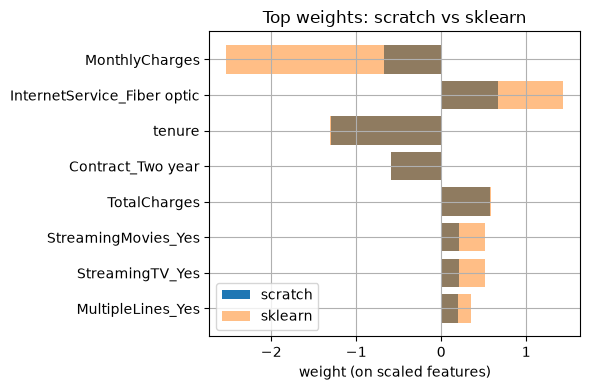

In [27]:
order = np.argsort(np.abs(sk2.coef_[0]))[-8:]                # 8 largest-magnitude weights
names = np.array(X.columns)[order]
plt.barh(names, w[order], label="scratch"); plt.barh(names, sk2.coef_[0][order], alpha=.5, label="sklearn")
plt.xlabel("weight (on scaled features)"); plt.legend(); plt.title("Top weights: scratch vs sklearn"); plt.tight_layout(); plt.show()

#### ðŸ“– How to read this plot

- **Axes:** y = feature name; x = its weight. Positive weight pushes toward churn, negative pushes away. Two overlapping bars per feature (scratch vs sklearn).
- **A good result looks like:** The two bars overlap exactly, meaning both implementations agree.
- **A bad result looks like:** Bars of different length or opposite sign, which would indicate a bug in our code.
- **What this plot tells us:** Short tenure and month-to-month / fibre-internet features push toward churn; long tenure and long contracts push away. The two implementations agree.

### ðŸ§  Check yourself

Why did we need `C=1e10` for a fair comparison?

<details><summary>ðŸ‘‰ Click for the answer</summary>

sklearn adds a regularisation penalty by default; our scratch model has none. A huge C turns the penalty almost off.

</details>

### Recap in 3 bullets

- Gradient of log-loss is wonderfully simple: (p − y)·x averaged over customers.
- Gradient descent = repeat: predict, compute gradient, step downhill with a learning rate.
- Our NumPy-only model matches sklearn, so we truly understand what the library does.

**If you remember only one thing:** logistic regression training is just 'predict, measure (p − y), nudge the weights' in a loop.

---
# ✅ Step 3 summary
**Recap in 3 bullets**
- We built sigmoid, loss, gradient descent and predict in pure NumPy.
- The 2D toy plot showed a straight decision boundary with probabilities fading smoothly across it.
- Our results match scikit-learn on both the toy and the churn data.

**If you remember only one thing:** gradient = (prediction − truth) × feature; step the opposite way.